In [1]:
import pandas as pd
import matplotlib.pyplot as plt

category_df = pd.read_csv(
    "../data/processed/category_sales_top15.csv"
)

change_df = pd.read_csv(
    "../data/processed/category_gmv_change.csv"
)

print("Category sales:", category_df.shape)
print("Category changes:", change_df.shape)

display(category_df.head())
display(change_df.head())

Category sales: (15, 7)
Category changes: (15, 8)


,category_name,item_count,product_count,order_count,gmv,avg_item_price,gmv_share_pct
0,health_beauty,9422,2380,8610,1229557.50,130.50,9.33
1,watches_gifts,5855,1297,5491,1163465.91,198.71,8.83
2,bed_bath_table,10945,2987,9267,1022955.77,93.46,7.76
3,sports_leisure,8414,2812,7513,952840.40,113.24,7.23
4,computers_accessories,7632,1598,6518,888055.59,116.36,6.74


,category_name,july_items,aug_items,july_gmv,aug_gmv,gmv_change,july_share_pct,aug_share_pct
0,watches_gifts,521,411,95164.79,69767.06,-25397.73,10.96,8.32
1,health_beauty,770,835,103524.22,119391.01,15866.79,11.93,14.24
2,telephony,221,271,26492.68,36572.91,10080.23,3.05,4.36
3,garden_tools,177,136,25639.88,16314.70,-9325.18,2.95,1.95
4,construction_tools_construction,115,162,15237.47,22917.16,7679.69,1.76,2.73


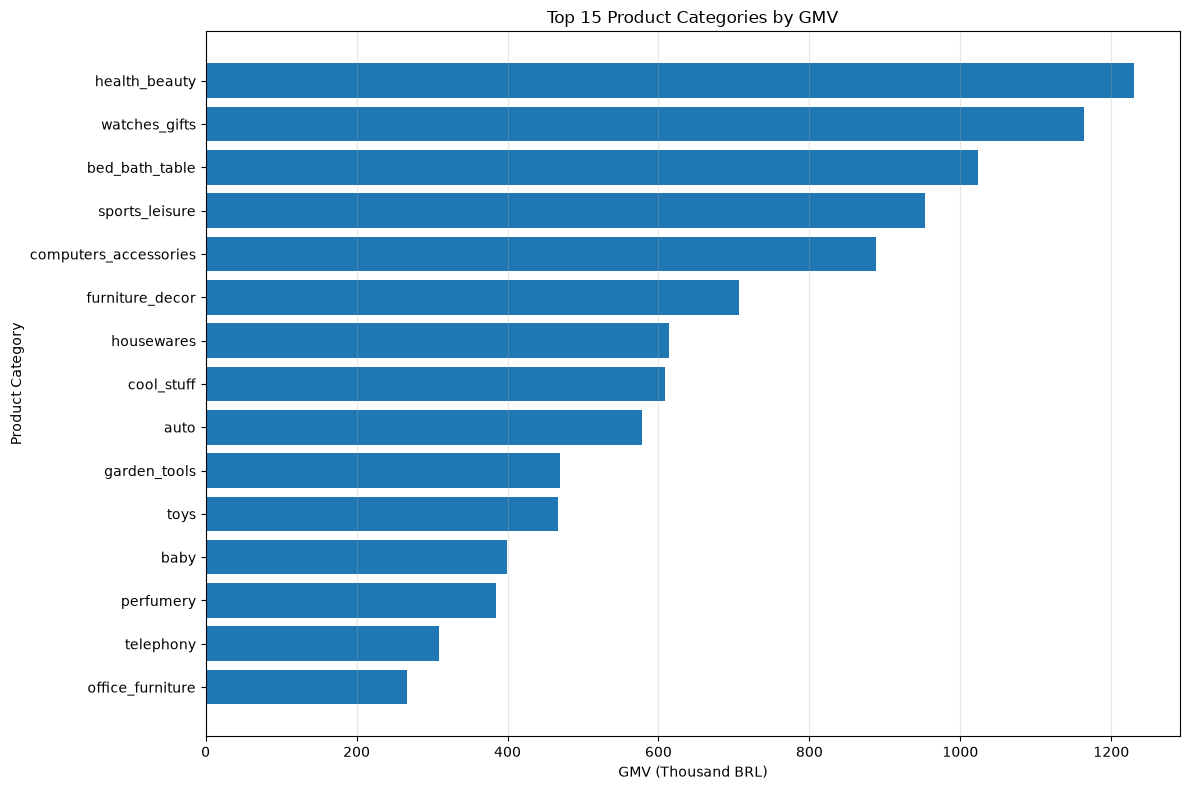

In [2]:
top15 = category_df.sort_values("gmv")

plt.figure(figsize=(12, 8))

plt.barh(
    top15["category_name"],
    top15["gmv"] / 1000
)

plt.title("Top 15 Product Categories by GMV")
plt.xlabel("GMV (Thousand BRL)")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/category_top15_gmv.png",
    dpi=300
)

plt.show()

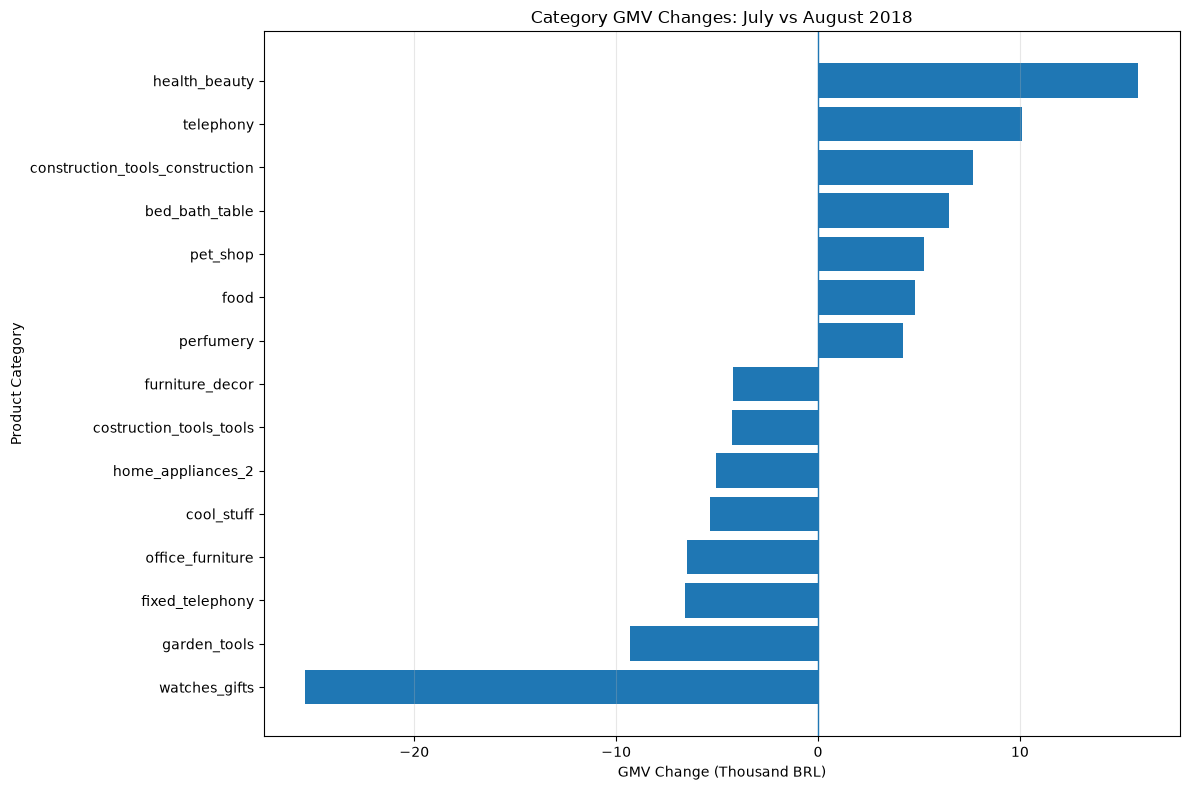

In [3]:
change_plot = change_df.sort_values("gmv_change")

plt.figure(figsize=(12, 8))

plt.barh(
    change_plot["category_name"],
    change_plot["gmv_change"] / 1000
)

plt.axvline(0, linewidth=1)

plt.title("Category GMV Changes: July vs August 2018")
plt.xlabel("GMV Change (Thousand BRL)")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/category_gmv_change.png",
    dpi=300
)

plt.show()

## 商品品类分析总结

### 1. 商品销售结构

平台商品销售额存在一定的头部集中现象。

- Top 5 品类贡献 39.88% 的 GMV。
- Top 10 品类贡献 62.47% 的 GMV。
- Top 15 品类贡献 76.33% 的 GMV。

其中，health_beauty、watches_gifts 和 bed_bath_table
是交易额最高的三个品类。

### 2. 商品数量与价格差异

不同品类的销售贡献模式存在差异。

bed_bath_table 商品明细数量较多，
但平均明细金额相对较低。

watches_gifts 商品明细数量相对较少，
但平均明细金额较高，因此具有较高的 GMV 贡献。

说明商品销售额同时受到交易数量和商品金额水平的影响。

### 3. 商品品类结构变化

2018 年 8 月与 7 月相比：

- watches_gifts GMV 减少 R$25,397.73。
- health_beauty GMV 增加 R$15,866.79。
- telephony GMV 增加 R$10,080.23。

不同品类之间存在明显的销售表现分化。

部分品类下降超过其他品类的增长，
共同表现为平台整体 GMV 下降。

### 4. AOV 变化分析

2018 年 8 月 AOV 环比下降 6.31%。

进一步分解发现：

- 每单平均商品明细数下降约 0.53%。
- 平均商品明细金额下降约 5.81%。

平均商品明细金额下降是 AOV 下滑的主要算术来源。

该现象可能受到商品品类结构、
商品组合或价格变化的影响，尚需进一步验证。

### 5. 综合业务结论

1. 平台 GMV 存在一定头部品类集中现象。
2. 不同品类的交易额贡献受到销售数量和金额水平共同影响。
3. 2018 年 8 月的 GMV 下降伴随着明显的品类销售结构变化。
4. AOV 下滑主要体现为平均商品明细金额降低，而非每单商品明细数量明显减少。
5. 商品结构变化与 AOV 波动之间的关系值得进一步研究。

### 6. 分析局限

- 本次主要采用描述性分析，不能证明因果关系。
- 商品明细数量不等于去重商品 SKU 数量。
- 平均商品明细金额变化不等同于同款商品价格变化。
- 数据末期可能受到订单履约观察期不足的影响。
- 部分商品存在类别信息缺失，分析时保留为 unknown。

In [5]:
seller_df = pd.read_csv(
    "../data/processed/seller_sales_top15.csv"
)

concentration_df = pd.read_csv(
    "../data/processed/seller_concentration.csv"
)

print(seller_df.shape)
print(concentration_df.shape)

display(seller_df.head())
display(concentration_df)

(15, 7)
(1, 6)


,seller_id,item_count,order_count,product_count,gmv,avg_item_price,gmv_share_pct
0,4869f7a5dfa277a7dca6462dcf3b52b2,1148,1124,94,226987.93,197.72,1.72
1,53243585a1d6dc2643021fd1853d8905,400,348,23,217940.44,544.85,1.65
2,4a3ca9315b744ce9f8e9374361493884,1949,1772,394,196882.12,101.02,1.49
3,fa1c13f2614d7b5c4749cbc52fecda94,579,578,284,190917.14,329.74,1.45
4,7c67e1448b00f6e969d365cea6b010ab,1355,973,197,186570.05,137.69,1.42


,active_sellers,total_gmv,top5_share_pct,top10_share_pct,top15_share_pct,top50_share_pct
0,2945,13181027.13,7.73,13.3,17.65,33.23


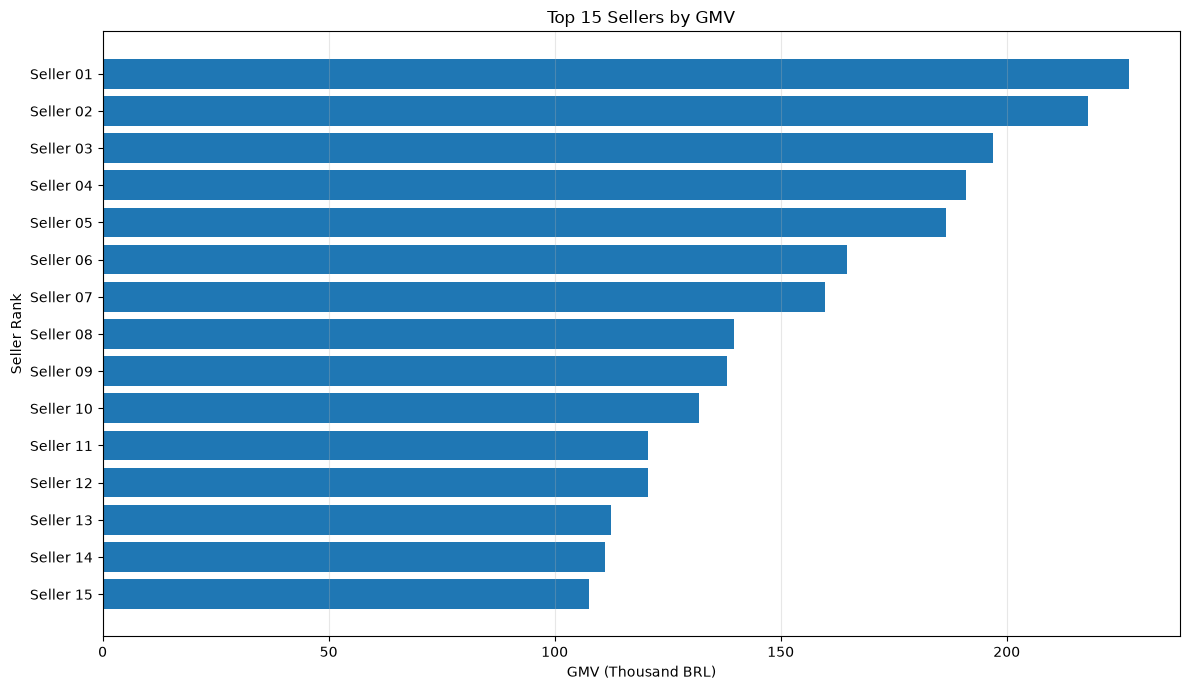

In [6]:
seller_plot = seller_df.sort_values(
    "gmv", ascending=False
).reset_index(drop=True)

seller_plot["seller_label"] = [
    f"Seller {i:02d}"
    for i in range(1, len(seller_plot) + 1)
]

plt.figure(figsize=(12, 7))

plt.barh(
    seller_plot["seller_label"][::-1],
    seller_plot["gmv"][::-1] / 1000
)

plt.title("Top 15 Sellers by GMV")
plt.xlabel("GMV (Thousand BRL)")
plt.ylabel("Seller Rank")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/seller_top15_gmv.png",
    dpi=300
)

plt.show()


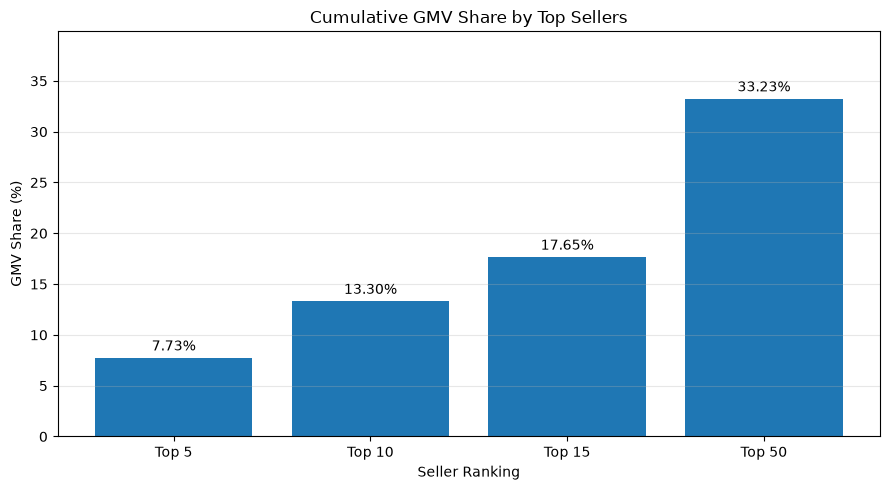

In [7]:
row = concentration_df.iloc[0]

labels = ["Top 5", "Top 10", "Top 15", "Top 50"]

shares = [
    row["top5_share_pct"],
    row["top10_share_pct"],
    row["top15_share_pct"],
    row["top50_share_pct"]
]

plt.figure(figsize=(9, 5))

bars = plt.bar(labels, shares)

plt.bar_label(
    bars,
    fmt="%.2f%%",
    padding=3
)

plt.title("Cumulative GMV Share by Top Sellers")
plt.xlabel("Seller Ranking")
plt.ylabel("GMV Share (%)")

plt.ylim(0, max(shares) * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/seller_concentration.png",
    dpi=300
)

plt.show()


## 商家销售分析总结

### 1. 商家销售规模

2017 年 1 月至 2018 年 8 月，平台共有 2,945 家活跃商家，
已送达商品交易额合计 R$13,181,027.13。

GMV 最高的商家贡献 R$226,987.93，占平台总交易额的 1.72%。

### 2. 商家销售集中度

平台商家 GMV 存在一定的头部集中现象。

- Top 5 商家贡献 7.73% 的 GMV。
- Top 10 商家贡献 13.30% 的 GMV。
- Top 15 商家贡献 17.65% 的 GMV。
- Top 50 商家贡献 33.23% 的 GMV。

Top 50 商家仅占活跃商家数量的约 1.70%，
却贡献了约三分之一的商品交易额。

说明平台销售额向头部商家集中，
但没有表现出对单一商家的高度依赖。

### 3. 商家经营模式差异

不同商家的销售贡献方式存在明显差异。

部分商家通过较高的平均商品明细金额实现较高 GMV，
另一些商家则主要依靠较大的商品交易数量。

商家销售的商品种类数量也存在明显差异。

说明商家 GMV 受到交易数量、商品金额水平
以及商品组合等因素的共同影响。

### 4. 商品品类与商家集中度比较

商品品类 Top 5 的 GMV 贡献率为 39.88%，
商家 Top 5 的 GMV 贡献率为 7.73%。

说明平台交易额相对集中于部分商品品类，
但在不同商家之间的分布相对分散。

由于品类和商家的实体数量不同，
该比较仅反映各自的头部贡献情况，
不能直接用于判断市场竞争程度。

### 5. 综合业务结论

1. 平台拥有较多活跃商家，没有明显的单一商家依赖。
2. 头部商家贡献了较高比例的交易额，存在一定销售集中现象。
3. 不同商家的交易数量、商品价格及商品组合存在差异。
4. 商品品类集中度与商家集中度表现不同。
5. 后续可以结合商家地域分布，进一步分析区域供给结构。

### 6. 分析局限

- GMV 不等同于商家实际利润或平台佣金收入。
- 当前分析没有考虑商家运营成本、利润率等指标。
- 商品明细数量不等于去重商品 SKU 数量。
- 商家参与订单数量不能直接累加为平台订单量。
- 当前分析属于描述性分析，不能直接证明经营模式的优劣。

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

customer_state_df = pd.read_csv(
    "../data/processed/customer_state_sales.csv"
)

seller_state_df = pd.read_csv(
    "../data/processed/seller_state_sales.csv"
)

print(customer_state_df.shape)
print(seller_state_df.shape)

display(customer_state_df.head())
display(seller_state_df.head())

(27, 6)
(22, 6)


,customer_state,valid_orders,unique_customers,gmv,aov,gmv_share_pct
0,SP,40406,39065,5055587.13,125.12,38.36
1,RJ,12310,11879,1751433.85,142.28,13.29
2,MG,11319,10969,1548206.88,136.78,11.75
3,RS,5328,5151,726373.92,136.33,5.51
4,PR,4903,4750,664048.00,135.44,5.04


,seller_state,active_sellers,order_count,gmv,gmv_share_pct,seller_share_pct
0,SP,1751,68489,8487299.48,64.39,59.46
1,PR,334,7478,1226347.62,9.30,11.34
2,MG,235,7714,975967.19,7.40,7.98
3,RJ,161,4190,813290.60,6.17,5.47
4,SC,184,3592,612709.38,4.65,6.25


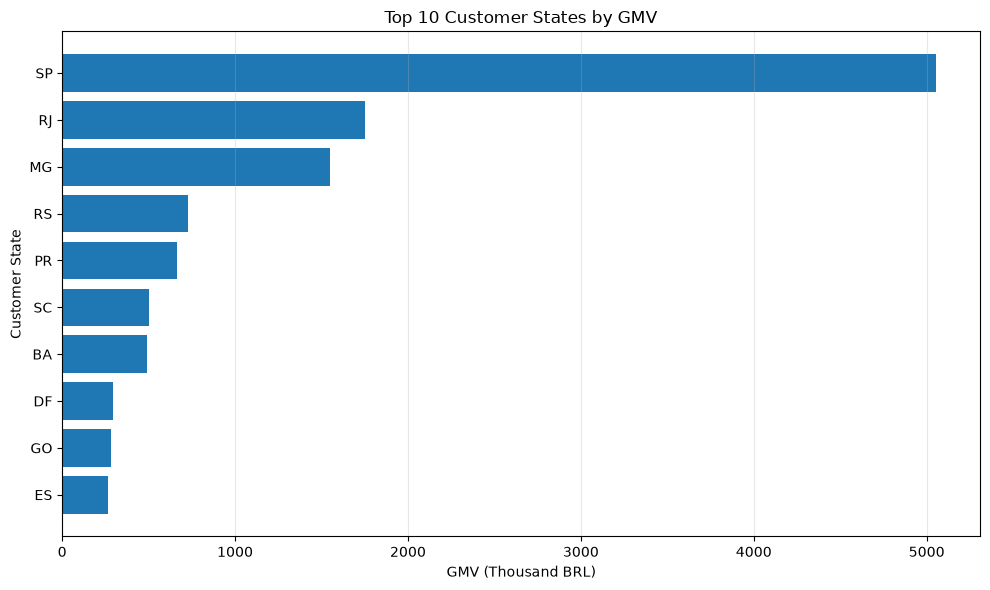

In [17]:
top10_states = customer_state_df.nlargest(10, "gmv")
top10_plot = top10_states.sort_values("gmv")

plt.figure(figsize=(10, 6))

plt.barh(
    top10_plot["customer_state"],
    top10_plot["gmv"] / 1000
)

plt.title("Top 10 Customer States by GMV")
plt.xlabel("GMV (Thousand BRL)")
plt.ylabel("Customer State")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/customer_state_top10_gmv.png",
    dpi=300
)

plt.show()

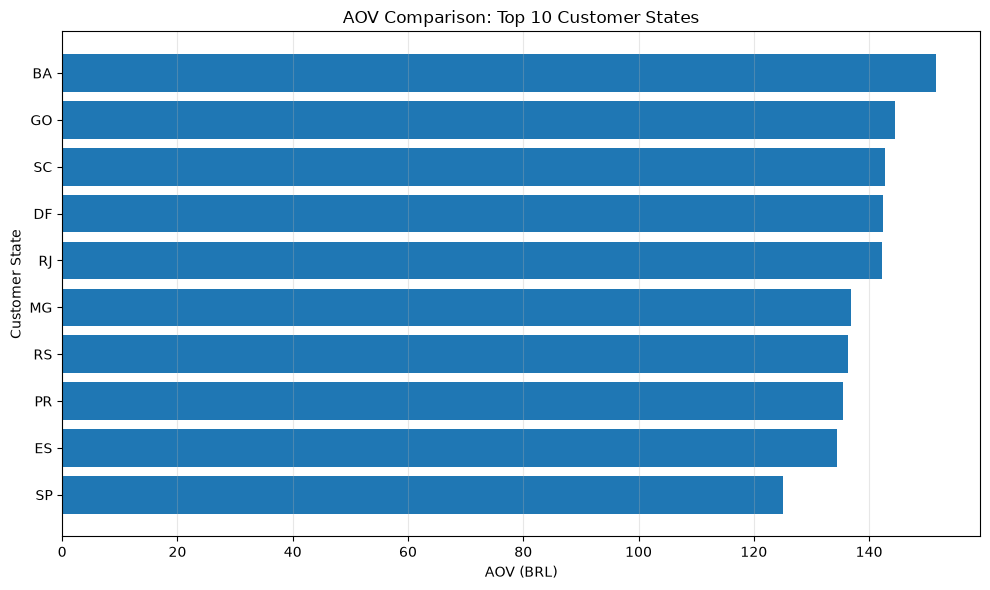

In [18]:
aov_plot = top10_states.sort_values("aov")

plt.figure(figsize=(10, 6))

plt.barh(
    aov_plot["customer_state"],
    aov_plot["aov"]
)

plt.title("AOV Comparison: Top 10 Customer States")
plt.xlabel("AOV (BRL)")
plt.ylabel("Customer State")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/customer_state_aov.png",
    dpi=300
)

plt.show()

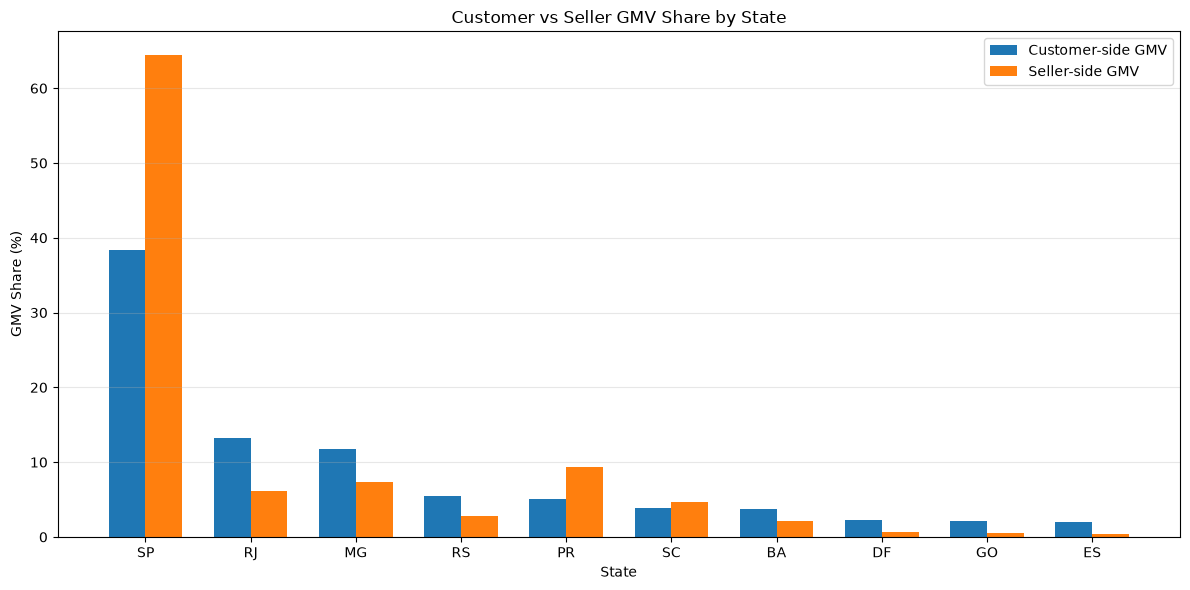

In [19]:
comparison = pd.merge(
    customer_state_df[
        ["customer_state", "gmv_share_pct"]
    ],
    seller_state_df[
        ["seller_state", "gmv_share_pct"]
    ],
    left_on="customer_state",
    right_on="seller_state",
    how="left",
    suffixes=("_customer", "_seller")
)

comparison["gmv_share_pct_seller"] = (
    comparison["gmv_share_pct_seller"].fillna(0)
)

comparison = comparison.nlargest(
    10, "gmv_share_pct_customer"
)

x = np.arange(len(comparison))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    comparison["gmv_share_pct_customer"],
    width,
    label="Customer-side GMV"
)

plt.bar(
    x + width / 2,
    comparison["gmv_share_pct_seller"],
    width,
    label="Seller-side GMV"
)

plt.xticks(x, comparison["customer_state"])

plt.title("Customer vs Seller GMV Share by State")
plt.xlabel("State")
plt.ylabel("GMV Share (%)")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/buyer_seller_state_gmv_share.png",
    dpi=300
)

plt.show()

## 第四阶段：商品与地区分析总结

### 1. 商品销售结构

平台商品交易额存在一定的头部集中现象。

- Top 5 品类贡献 39.88% 的 GMV。
- Top 10 品类贡献 62.47% 的 GMV。
- Top 15 品类贡献 76.33% 的 GMV。

其中 health_beauty、watches_gifts 和 bed_bath_table
是交易额最高的三个商品品类。

不同品类的销售贡献受到商品明细数量和金额水平共同影响。

### 2. 商品结构与 AOV 变化

2018 年 8 月，平台 GMV 环比下降 3.38%，
AOV 环比下降 6.31%。

品类分析发现：

- watches_gifts GMV 减少 R$25,397.73。
- health_beauty GMV 增加 R$15,866.79。
- telephony GMV 增加 R$10,080.23。

进一步分析发现：

- 每单平均商品明细数下降约 0.53%。
- 平均商品明细金额下降约 5.81%。

说明 AOV 下降主要表现为平均商品明细金额降低，
而非每单商品明细数量明显减少。

具体影响因素仍需结合商品组合与价格变化进一步验证。

### 3. 商家销售集中度

分析期间共有 2,945 家活跃商家。

- Top 5 商家贡献 7.73% 的 GMV。
- Top 15 商家贡献 17.65% 的 GMV。
- Top 50 商家贡献 33.23% 的 GMV。

平台商家存在一定头部集中现象，
但最高 GMV 商家仅贡献 1.72%，
没有表现出对单一商家的高度依赖。

不同商家的交易规模、商品数量和平均明细金额存在差异。

### 4. 地区交易规模

平台买家覆盖巴西全部 27 个州及联邦单位。

- SP 贡献 38.36% 的 GMV。
- RJ 贡献 13.29% 的 GMV。
- MG 贡献 11.75% 的 GMV。

前三个地区合计贡献 63.40% 的 GMV，
说明平台消费端交易额存在明显地域集中现象。

### 5. 地区客单价与商品结构

交易规模较大的地区不一定具有较高的 AOV。

SP 的 GMV 最高，但 AOV 为 R$125.12，
低于整体约 R$137.00 的水平。

不同地区的主要销售品类也存在一定差异。

SP、RJ、MG 的前三大品类相同，
但具体排名顺序不同。

PR 和 RS 的头部品类结构则有所不同。

这表明地区之间存在商品交易结构差异，
但不能直接代表消费者的主观偏好。

### 6. 买家与商家地域分布

平台商家分布于 22 个州。

SP 的商家侧 GMV 占比为 64.39%，
而买家侧 GMV 占比为 38.36%。

RJ 和 MG 的买家侧 GMV 占比则高于商家侧。

说明平台商品供给端与消费端的地域分布存在差异。

但目前不能直接据此计算跨州交易规模或物流成本。

### 7. 综合业务结论

1. 平台商品交易额存在一定的头部品类集中现象。
2. 商家销售额具有头部集中特征，但没有明显的单一商家依赖。
3. 2018 年 8 月 GMV 下降伴随商品品类结构变化。
4. AOV 下降主要表现为平均商品明细金额降低。
5. 消费端交易额主要集中在 SP、RJ、MG。
6. 商家侧交易额更加集中于 SP，供需两端地域结构不完全一致。

### 8. 分析局限

- GMV 不等同于平台实际收入或利润。
- 商品明细数量不等于去重商品 SKU 数量。
- 商品交易结构变化不能直接证明消费者偏好变化。
- 地区 GMV 占比差异不等同于跨州交易量。
- 数据末期可能存在订单履约观察期不足的问题。
- 当前分析属于描述性分析，不能直接证明因果关系。